Problema 9: Mercado financeiro - retornos

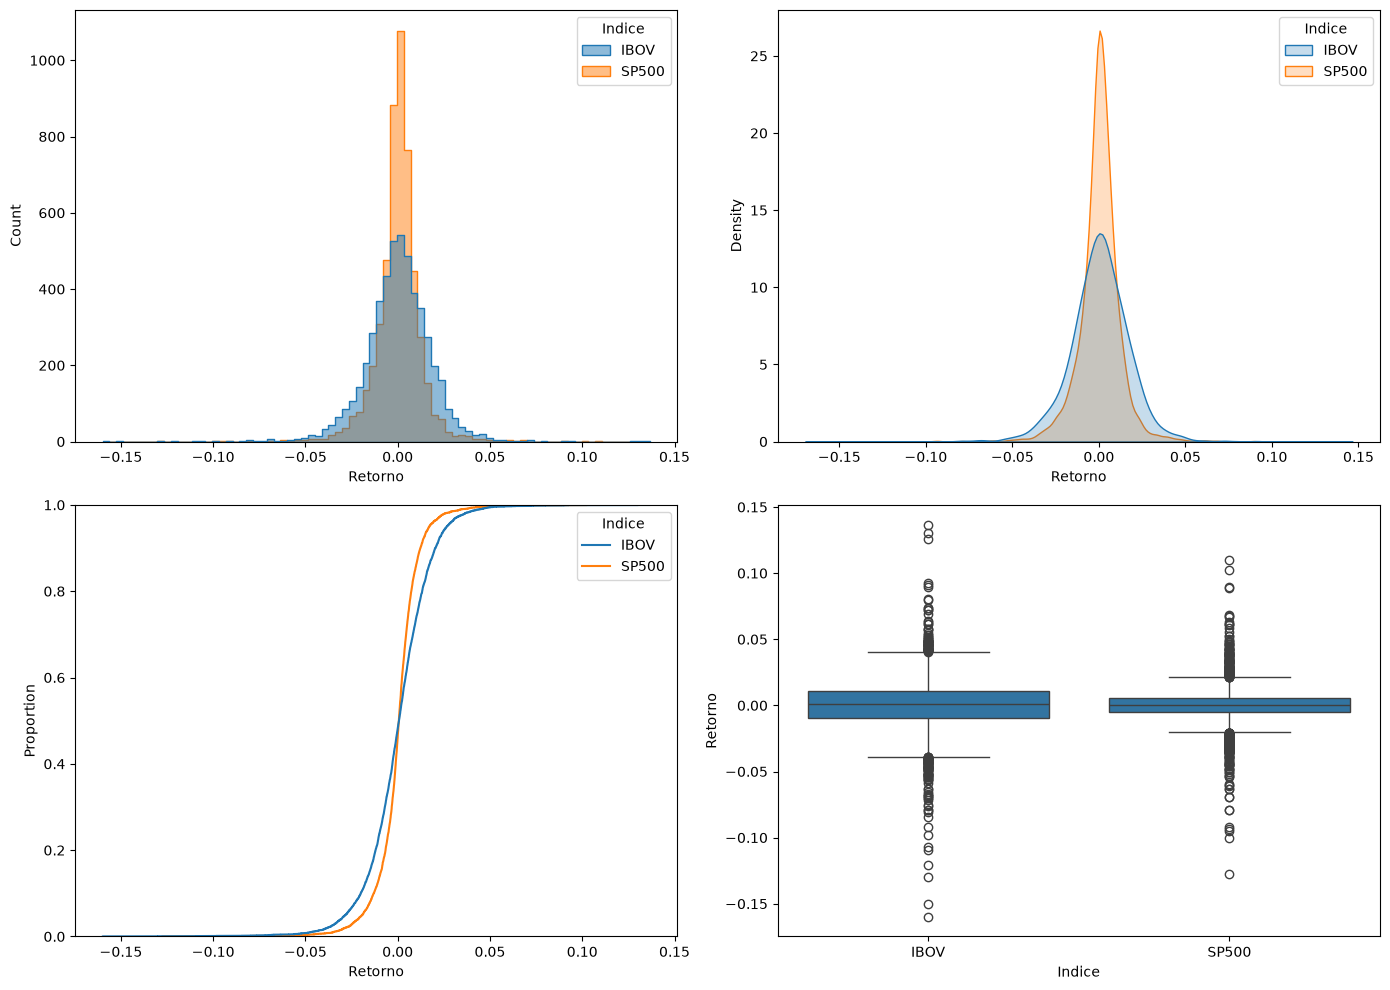

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url_mercado = "https://raw.githubusercontent.com/Rogerio-mack/Visualizacao-de-Dados-em-Python/main/data/sp500_ibov_2000.csv"
mercado = pd.read_csv(url_mercado)

# b) Cálculo de retornos Log
ret_ibov = np.log(mercado["IBOV"]).diff().dropna()
ret_sp500 = np.log(mercado["SP500"]).diff().dropna()

# DataFrame empilhado para facilitar
df_retornos = pd.DataFrame({'IBOV': ret_ibov, 'SP500': ret_sp500}).melt(var_name='Indice', value_name='Retorno')

# c, d, e, f) Subplots Multi-Visão
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_retornos, x='Retorno', hue='Indice', bins=80, alpha=0.5, element="step", ax=axes[0,0])
sns.kdeplot(df_retornos, x='Retorno', hue='Indice', fill=True, ax=axes[0,1])
sns.ecdfplot(df_retornos, x='Retorno', hue='Indice', ax=axes[1,0])
sns.boxplot(data=df_retornos, x='Indice', y='Retorno', ax=axes[1,1])

plt.tight_layout()
plt.show()

g) Comparativo e Variabilidade: O centro (mediana) de ambos orbita ao redor de zero, sendo simétricos. Contudo, a dispersão é o ponto-chave: O SP500 tem caudas substancialmente mais curtas e IQR comprimido.

h) Maior variabilidade: O índice IBOV apresenta largamente maior variabilidade (volatilidade ou risco), visto por caudas imensas e outliers severos para ambos os sentidos no box-plot.

i) Consistência: Totalmente consistente. O histograma/KDE do IBOV desenhou uma curva visivelmente mais "baixa e larga", que geometricamente traduz o alongamento de dispersão verificado no box-plot.

j) Utilidade em múltiplas abordagens: Combinações como esta garantem fiabilidade. KDE mostra sub-padrões, Box-plot entrega os limites precisos da "normalidade" do IQR, e Histograma ancora ao valor visual absoluto da amostra.